In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

from project_code.backends_library import run_on_local_simulator
from project_code.ansatz_library import custom_linear_cnot
from project_code.hamiltonian_library import custom_hamiltonian
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from matplotlib import pyplot as plt



In [2]:
number_of_qubits = 5
service, backend = run_on_local_simulator()
hamiltonian = custom_hamiltonian(2, 3, 15)
# ansatz = EfficientSU2(hamiltonian.num_qubits)
# ansatz.decompose().draw("mpl", style="iqp")
ansatz, _ = custom_linear_cnot(number_of_qubits)

In [3]:
print(hamiltonian.to_matrix())

[[  36.+0.j    0.+0.j    0.+0.j ...    0.+0.j    0.+0.j    0.+0.j]
 [   0.+0.j   36.+0.j    0.+0.j ...    0.+0.j    0.+0.j    0.+0.j]
 [   0.+0.j    0.+0.j  -36.+0.j ...    0.+0.j    0.+0.j    0.+0.j]
 ...
 [   0.+0.j    0.+0.j    0.+0.j ...  -20.+0.j    0.+0.j    0.+0.j]
 [   0.+0.j    0.+0.j    0.+0.j ...    0.+0.j  324.+0.j    0.+0.j]
 [   0.+0.j    0.+0.j    0.+0.j ...    0.+0.j    0.+0.j -412.+0.j]]


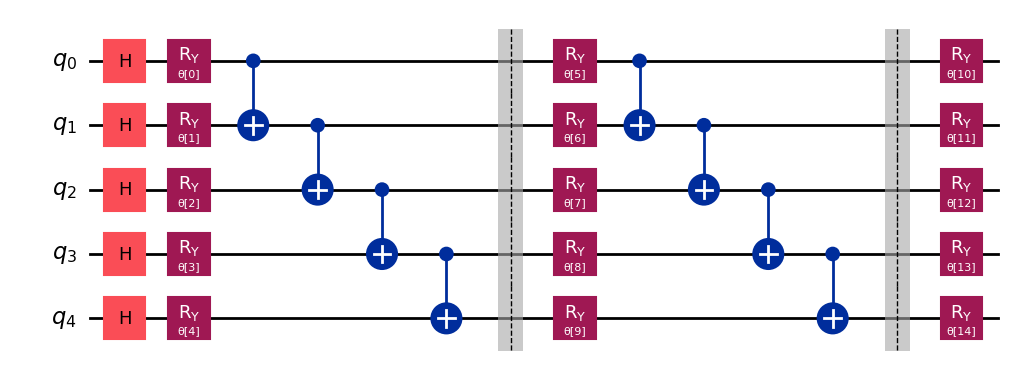

In [4]:
ansatz.draw("mpl")


In [5]:
target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

ansatz_isa = pm.run(ansatz)

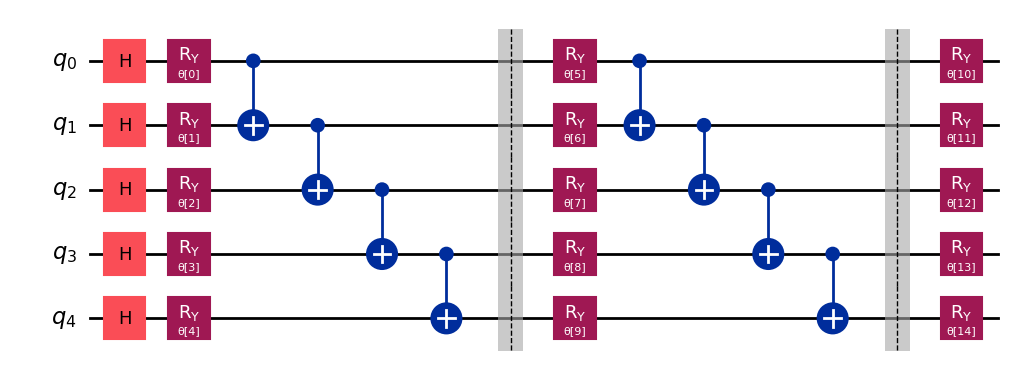

In [6]:
ansatz_isa.draw(output="mpl", idle_wires=False, style="iqp")

In [7]:
hamiltonian_isa = hamiltonian.apply_layout(layout=ansatz_isa.layout)

In [8]:
def cost_func(params, ansatz, hamiltonian, estimator):
    """Return estimate of energy from estimator

    Parameters:
        params (ndarray): Array of ansatz parameters
        ansatz (QuantumCircuit): Parameterized ansatz circuit
        hamiltonian (SparsePauliOp): Operator representation of Hamiltonian
        estimator (EstimatorV2): Estimator primitive instance
        cost_history_dict: Dictionary for storing intermediate results

    Returns:
        float: Energy estimate
    """
    pub = (ansatz, [hamiltonian], [params])
    result = estimator.run(pubs=[pub]).result()
    energy = result[0].data.evs[0]

    cost_history_dict["iters"] += 1
    cost_history_dict["prev_vector"] = params
    cost_history_dict["cost_history"].append(energy)
    print(f"Iters. done: {cost_history_dict['iters']} [Current cost: {energy}]")

    return energy

In [9]:
import numpy as np

cost_history_dict = {
    "prev_vector": None,
    "iters": 0,
    "cost_history": [],
}

x0 = 2 * np.pi * np.random.random(ansatz.num_parameters)


In [10]:

from qiskit_ibm_runtime import Session
from scipy.optimize import minimize

with Session(backend=backend) as session:
    estimator = Estimator(mode=session)
    estimator.options.default_shots = 10000

    res = minimize(
        cost_func,
        x0,
        args=(ansatz_isa, hamiltonian_isa, estimator),
        method="cobyla",
    )

Iters. done: 1 [Current cost: 237.8192]
Iters. done: 2 [Current cost: 267.32380000000006]
Iters. done: 3 [Current cost: 215.39960000000002]
Iters. done: 4 [Current cost: 236.41760000000002]
Iters. done: 5 [Current cost: 161.87780000000004]
Iters. done: 6 [Current cost: 213.4074]
Iters. done: 7 [Current cost: 192.30279999999996]
Iters. done: 8 [Current cost: 131.10260000000002]
Iters. done: 9 [Current cost: 133.29580000000004]
Iters. done: 10 [Current cost: 79.67620000000005]
Iters. done: 11 [Current cost: 107.6296]
Iters. done: 12 [Current cost: 204.8032]
Iters. done: 13 [Current cost: 79.9348]
Iters. done: 14 [Current cost: 88.62099999999998]
Iters. done: 15 [Current cost: 174.08679999999998]
Iters. done: 16 [Current cost: 79.64699999999999]
Iters. done: 17 [Current cost: 73.887]
Iters. done: 18 [Current cost: 72.40260000000002]
Iters. done: 19 [Current cost: 152.52259999999998]
Iters. done: 20 [Current cost: 82.55959999999999]
Iters. done: 21 [Current cost: 128.0204]
Iters. done: 22 

In [11]:
res

 message: Optimization terminated successfully.
 success: True
  status: 1
     fun: -29.63460000000002
       x: [ 2.335e+00  3.048e+00 ...  4.623e+00  7.171e+00]
    nfev: 226
   maxcv: 0.0

In [12]:
cost_history_dict["prev_vector"] == res.x

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True])

In [13]:
cost_history_dict["iters"] == res.nfev

True

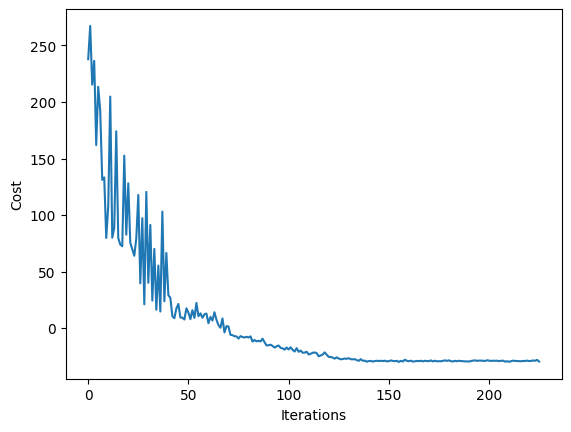

In [14]:
fig, ax = plt.subplots()
ax.plot(range(cost_history_dict["iters"]), cost_history_dict["cost_history"])
ax.set_xlabel("Iterations")
ax.set_ylabel("Cost")
plt.draw()

# Post Process For Factors

In [15]:
optimal_params = res.x
optimal_params

array([ 2.33509003,  3.04846012,  0.20566965,  3.19899562,  3.86207115,
        3.90407704,  2.14098461,  4.82447026,  3.31043591, -0.12959355,
       -0.10967757,  2.89238317,  3.28730187,  4.62339545,  7.17102575])

In [16]:
# 1. Bind parameters to the ansatz
bound_circuit = ansatz.assign_parameters(optimal_params)

# 2. Add measurement if not already added
bound_circuit.measure_all()

# 3. Transpile the circuit for the Aer simulator
simulator = AerSimulator()
compiled_circuit = transpile(bound_circuit, simulator)

# 4. Run the circuit
job = simulator.run(compiled_circuit, shots=10000)
result = job.result()

# 5. Get the measurement counts
statistics = result.get_counts()
# most_likely_bitstring = max(statistics, key=statistics.get)

# print("Most likely bitstring:", most_likely_bitstring)

In [17]:
for key in result.get_counts().keys():
    p, q = int(key[:2], 2), int(key[2:], 2)
    if p * q == 15:
        print("found: ", p, q)